<a href="https://colab.research.google.com/github/N0t60rnyY3t/proiect-facultate-PI/blob/main/%5BPI%5D_Proiect_Segmentare_Organe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# I. Montare Drive si descarcare dataset
---
De rulat de fiecare data la inceputul unei sesiuni noi!

Pasi:
I. Montare -> II. Descarcare nnUNet in sesiune-> M4. Antrenare Model -> M5. Inferenta -> M6. Post-procesare / Afisare






In [1]:
import os
from google.colab import drive

# 1. Montăm Google Drive-ul (force_remount asigură reconectarea dacă se blochează)
drive.mount('/content/drive', force_remount=True, timeout_ms=600000)

# 2. Definim calea exactă către folderul tău de proiect
my_custom_folder = '/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data'

# 3. Ne asigurăm că folderele principale există (nu strică nimic dacă ele există deja)
os.makedirs(os.path.join(my_custom_folder, 'nnUNet_raw'), exist_ok=True)
os.makedirs(os.path.join(my_custom_folder, 'nnUNet_preprocessed'), exist_ok=True)
os.makedirs(os.path.join(my_custom_folder, 'nnUNet_results'), exist_ok=True)

# 4. Setăm variabilele de mediu obligatorii pentru nnU-Net
os.environ['nnUNet_raw'] = os.path.join(my_custom_folder, 'nnUNet_raw')
os.environ['nnUNet_preprocessed'] = os.path.join(my_custom_folder, 'nnUNet_preprocessed')
os.environ['nnUNet_results'] = os.path.join(my_custom_folder, 'nnUNet_results')

# 5. Mesaj de confirmare
print("\n--- Setup Inițializare Complet ---")
print("Căile nnU-Net sunt setate către:")
print(f"- Raw: {os.environ['nnUNet_raw']}")
print(f"- Preprocessed: {os.environ['nnUNet_preprocessed']}")
print(f"- Results: {os.environ['nnUNet_results']}")

Mounted at /content/drive

--- Setup Inițializare Complet ---
Căile nnU-Net sunt setate către:
- Raw: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw
- Preprocessed: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_preprocessed
- Results: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_results


### a. Descarcare dataset CHAOS



In [2]:
import os

# Calea corectată, exact cum e în Drive-ul tău
my_custom_folder = '/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data'

# Rescriem variabilele de mediu
os.environ['nnUNet_raw'] = os.path.join(my_custom_folder, 'nnUNet_raw')
os.environ['nnUNet_preprocessed'] = os.path.join(my_custom_folder, 'nnUNet_preprocessed')
os.environ['nnUNet_results'] = os.path.join(my_custom_folder, 'nnUNet_results')

print("Căile au fost actualizate corect:")
print(os.environ['nnUNet_raw'])

# 1. Navigăm în folderul principal de date brute
%cd "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw"

# 2. Creăm un folder dedicat și separat doar pentru datele brute CHAOS
!mkdir -p CHAOS_Raw_Data

# 3. Intrăm în noul folder creat
%cd CHAOS_Raw_Data

# 4. Descărcăm setul CHAOS de pe Zenodo
print("Începe descărcarea setului CHAOS...")
!wget -O CHAOS_Test_Sets.zip "https://zenodo.org/records/3431873/files/CHAOS_Test_Sets.zip?download=1"

# 5. Dezarhivăm conținutul
print("Dezarhivăm datele CHAOS...")
!unzip -q CHAOS_Test_Sets.zip

# 6. Ștergem arhiva ZIP pentru a păstra Drive-ul curat
print("Ștergem arhiva ZIP...")
!rm CHAOS_Test_Sets.zip

print("Setul de date CHAOS a fost descărcat și separat cu succes!")


Căile au fost actualizate corect:
/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw
/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw
/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/CHAOS_Raw_Data
Începe descărcarea setului CHAOS...
--2026-11-12 10:40:57--  https://zenodo.org/records/3431873/files/CHAOS_Test_Sets.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 188.185.47.192, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1091803676 (1.0G) [application/octet-stream]
Saving to: ‘CHAOS_Test_Sets.zip’

CHAOS_Test_Sets.zip   0%[                    ]   3.61M   531KB/s    eta 32m 46s^C
Dezarhivăm datele CHAOS...
[CHAOS_Test_Sets.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the ce

### b. Descarcare dataset AMOS

In [ ]:
# AMOS - Abdominal Multi Organ Segmentation Dataset

# 1. Ne asigurăm că suntem în folderul corect din Drive
%cd "/content/drive/MyDrive/[PI] Proiect Segmentare Organe/nnunet_data/nnUNet_raw"

# 2. Descărcăm setul AMOS22 Training (aprox 38 GB)
# Am folosit link-ul oficial de OneDrive oferit de autori
print("Descarca setul AMOS22...")
!wget -O amos22.zip "https://zenodo.org/records/7155725/files/amos22.zip?download=1"

# 3. Dezarhivăm datele direct în Drive
print("Dezarhivăm datele (poate dura 15-20 de minute pentru zeci de mii de fișiere)...")
!unzip -q amos22.zip -d AMOS_Dataset

# 4. Curățăm spațiul (ștergem arhiva originală descărcată pentru a elibera 38 GB)
print("Ștergem arhiva pentru a face curățenie...")
!rm amos22.zip

print("Descărcarea și dezarhivarea sunt finalizate cu succes!")

[Errno 2] No such file or directory: '/content/drive/MyDrive/[PI] Proiect Segmentare Organe/nnunet_data/nnUNet_raw'
/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/CHAOS_Raw_Data
Descarca setul AMOS22...
--2026-11-12 10:12:00--  https://zenodo.org/records/7155725/files/amos22.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.51.60, 188.185.47.192, 188.185.45.63, ...
Connecting to zenodo.org (zenodo.org)|188.185.51.60|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 24234336519 (23G) [application/octet-stream]
Saving to: ‘amos22.zip’

amos22.zip           15%[==>                 ]   3.56G  2.47MB/s    eta 2h 28m 

# II. Descarcare nnUNet in proiect

---
1. Montare drive si setup la cai
2. Instalare pachet nnUNet in mediu temporat collab
3. Verificare instalare
---
* Trebuie parcurse la fiecare restart de sesiun collab!

In [2]:
import os
from google.colab import drive

# 1. Montăm Google Drive
drive.mount('/content/drive')

# 2. Definim calea ta exactă din Drive
my_custom_folder = '/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data'

# 3. Informăm framework-ul nnU-Net unde sunt folderele
os.environ['nnUNet_raw'] = os.path.join(my_custom_folder, 'nnUNet_raw')
os.environ['nnUNet_preprocessed'] = os.path.join(my_custom_folder, 'nnUNet_preprocessed')
os.environ['nnUNet_results'] = os.path.join(my_custom_folder, 'nnUNet_results')

print("Căile nnU-Net au fost setate către Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Căile nnU-Net au fost setate către Google Drive!


In [3]:
!pip install nnunetv2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 119.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 67.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 132.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.7/27.7 MB 148.5 MB/s  0:00:00
  Attempting uninstall: timm
    Found existing installation: timm 1.0.31
    Uninstalling timm-1.0.31:
      Successfully uninstalled timm-1.0.31
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [nnunetv2]


In [4]:
# Afiseaza variabilele de mediu ale nnU-Net
!nnUNetv2_plan_and_preprocess -h

usage: nnUNetv2_plan_and_preprocess [-h] [-d D [D ...]] [-fpe FPE]
                                    [-npfp NPFP] [--verify_dataset_integrity]
                                    [--no_pp] [--clean] [-pl PL]
                                    [-gpu_memory_target GPU_MEMORY_TARGET]
                                    [-preprocessor_name PREPROCESSOR_NAME]
                                    [-overwrite_target_spacing OVERWRITE_TARGET_SPACING [OVERWRITE_TARGET_SPACING ...]]
                                    [-overwrite_plans_name OVERWRITE_PLANS_NAME]
                                    [-c C [C ...]] [-np NP [NP ...]]
                                    [--verbose] [--no_pbar]

options:
  -h, --help            show this help message and exit
  -d D [D ...]          [REQUIRED] List of dataset IDs. Example: 2 4 5. This
                        will run fingerprint extraction, experiment planning
                        and preprocessing for these datasets. Can of course
              

# M1 - Formatare si Standardizare
---
Modulul 1 - Formatare și Standardizare
* Transforma imaginile DICOM intr-un singur fisier .nii.gz
(formatul citit de nnUNet)
* Stabilim etichetele pentru diferitele tipuri de organe si tip de scanare

### a. Pregatire fisiere CHAOS - CT

Etichetare scanari pentru **CHAOS CT**

In [ ]:
import os
import json

# 1. Definim calea pentru noul dataset
base_raw = os.environ['nnUNet_raw']
task_name = 'Dataset002_CHAOS'
task_folder = os.path.join(base_raw, task_name)

# 2. Structura interna
os.makedirs(os.path.join(task_folder, 'imagesTr'), exist_ok=True) # Aici punem CT-urile (.nii.gz)
os.makedirs(os.path.join(task_folder, 'labelsTr'), exist_ok=True) # Aici punem Mastile (.nii.gz)

# 3. Reguli dataset pentru CHAOS CT (exista marcaje doar pentru Ficat)
dataset_json = {
    "channel_names": {
        "0": "CT"
    },
    "labels": {
        "background": 0,
        "liver": 1
    },
    "numTraining": 0,
    "file_ending": ".nii.gz"
}

# 4. Salveaza fisierul JSON in folderul dataset
with open(os.path.join(task_folder, 'dataset.json'), 'w') as f:
    json.dump(dataset_json, f, indent=4)

print(f"Structura pentru {task_name} a fost creată cu succes!")
print("Locație:", task_folder)

Structura pentru Dataset002_CHAOS a fost creată cu succes!
Locație: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/Dataset002_CHAOS


Formare fisier 3D (.nii.gz) din imaginile 2D (DICOM) pentru **CHAOS CT**

In [ ]:
!pip install dicom2nifti

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 13.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 36.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [dicom2nifti]


In [ ]:
import os
import dicom2nifti

# Path-uri  pentru fisiere
raw_chaos_ct_dir = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/CHAOS_Raw_Data/Train_Sets/CT"
imagesTr_dir = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/Dataset002_CHAOS/imagesTr"

print("Transformarea feliilor DICOM în volume 3D NIfTI\n")

# Lista cu toti pacientii din folderul CT
# Ne asiguram ca luam doar folderele (ignoram eventuale fisiere ascunse)
pacienti = [p for p in os.listdir(raw_chaos_ct_dir) if os.path.isdir(os.path.join(raw_chaos_ct_dir, p))]

contor = 0
for pacient_id in sorted(pacienti, key=int):
    dicom_folder = os.path.join(raw_chaos_ct_dir, pacient_id, "DICOM_anon")

    if os.path.exists(dicom_folder):
        # nnU-Net cere formatul Prefix_ID_0000.nii.gz (0000 indica faptul ca e prima imagine a pacientului)
        # Folosim zfill(3) ca sa formatam '1' ca '001'
        nume_nifti = f"CHAOS_{int(pacient_id):03d}_0000.nii.gz"
        output_file = os.path.join(imagesTr_dir, nume_nifti)

        print(f"Procesez pacientul {pacient_id} -> {nume_nifti}...")

        try:
            # Convertesc folder DICOM intr-un singur fisier NIfTI 3D
            dicom2nifti.dicom_series_to_nifti(dicom_folder, output_file, reorient_nifti=True)
            contor += 1
        except Exception as e:
            print(f"Eroare la pacientul {pacient_id}: {e}")

print(f"\nGata! Am sudat volumele pentru {contor} pacienti si au fost salvate imagesTr.")

Începem sudarea feliilor DICOM în volume 3D NIfTI...

Procesăm pacientul 1 -> CHAOS_001_0000.nii.gz...
Procesăm pacientul 2 -> CHAOS_002_0000.nii.gz...
Procesăm pacientul 5 -> CHAOS_005_0000.nii.gz...
Procesăm pacientul 6 -> CHAOS_006_0000.nii.gz...
Procesăm pacientul 8 -> CHAOS_008_0000.nii.gz...
Procesăm pacientul 10 -> CHAOS_010_0000.nii.gz...
Procesăm pacientul 14 -> CHAOS_014_0000.nii.gz...
Procesăm pacientul 16 -> CHAOS_016_0000.nii.gz...
Procesăm pacientul 18 -> CHAOS_018_0000.nii.gz...
Procesăm pacientul 19 -> CHAOS_019_0000.nii.gz...
Procesăm pacientul 21 -> CHAOS_021_0000.nii.gz...
Procesăm pacientul 22 -> CHAOS_022_0000.nii.gz...
Procesăm pacientul 23 -> CHAOS_023_0000.nii.gz...
Procesăm pacientul 24 -> CHAOS_024_0000.nii.gz...
Procesăm pacientul 25 -> CHAOS_025_0000.nii.gz...
Procesăm pacientul 26 -> CHAOS_026_0000.nii.gz...
Procesăm pacientul 27 -> CHAOS_027_0000.nii.gz...
Procesăm pacientul 28 -> CHAOS_028_0000.nii.gz...
Procesăm pacientul 29 -> CHAOS_029_0000.nii.gz...
P

Transformare masti adnotate PNG in fisiere 3D pentru retea

In [ ]:
import os
import numpy as np
import nibabel as nib
from PIL import Image
import json

# 1. Definim căile
raw_chaos_ct_dir = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/CHAOS_Raw_Data/Train_Sets/CT"
imagesTr_dir = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/Dataset002_CHAOS/imagesTr"
labelsTr_dir = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/Dataset002_CHAOS/labelsTr"
json_path = "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/nnunet_data/nnUNet_raw/Dataset002_CHAOS/dataset.json"

print("Începem sudarea măștilor PNG...\n")

pacienti = [p for p in os.listdir(raw_chaos_ct_dir) if os.path.isdir(os.path.join(raw_chaos_ct_dir, p))]
contor = 0

for pacient_id in sorted(pacienti, key=int):
    ground_folder = os.path.join(raw_chaos_ct_dir, pacient_id, "Ground")

    # Căutăm imaginea sursă pentru a-i împrumuta metadatele
    nume_imagine = f"CHAOS_{int(pacient_id):03d}_0000.nii.gz"
    cale_imagine = os.path.join(imagesTr_dir, nume_imagine)

    # Numele măștii cerut de nnU-Net (FĂRĂ _0000)
    nume_eticheta = f"CHAOS_{int(pacient_id):03d}.nii.gz"
    cale_eticheta = os.path.join(labelsTr_dir, nume_eticheta)

    if os.path.exists(ground_folder) and os.path.exists(cale_imagine):
        print(f"Procesăm masca pacientului {pacient_id} -> {nume_eticheta}")

        # 2. Citim fișierul CT cu nibabel pentru a-i accesa matricea spațială (affine)
        nii_img = nib.load(cale_imagine)
        img_data = nii_img.get_fdata()

        # Creăm un bloc de date 3D gol pentru mască
        mask_vol = np.zeros_like(img_data, dtype=np.uint8)

        # Luăm PNG-urile sortate alfabetic (reprezintă feliile de la bază la vârf)
        png_files = sorted([f for f in os.listdir(ground_folder) if f.endswith('.png')])

        for z, png_file in enumerate(png_files):
            if z >= mask_vol.shape[2]:
                break # Prevenim mismatch-uri

            png_path = os.path.join(ground_folder, png_file)

            # Citim imaginea
            slice_2d = np.array(Image.open(png_path))

            # Corecție de orientare: aliniem axele (Rânduri, Coloane) cu formatul NIfTI (X, Y)
            slice_2d = np.transpose(slice_2d, (1, 0))

            # Binarizare: ficatul capătă valoarea exactă 1 (restul 0)
            slice_2d = (slice_2d > 0).astype(np.uint8)

            # Inserăm felia în blocul 3D pe axa Z
            mask_vol[:, :, z] = slice_2d

        # 3. Împachetăm masca folosind header-ul și coordonatele de la CT
        nii_mask = nib.Nifti1Image(mask_vol, affine=nii_img.affine, header=nii_img.header)
        nib.save(nii_mask, cale_eticheta)
        contor += 1

# 4. Actualizăm automat numărul de pacienți în dataset.json
if os.path.exists(json_path):
    with open(json_path, 'r') as f:
        ds = json.load(f)
    ds['numTraining'] = contor
    with open(json_path, 'w') as f:
        json.dump(ds, f, indent=4)
    print(f"\nAm actualizat dataset.json: numTraining setat la {contor}.")

print("\nGata! Măștile au fost procesate în labelsTr.")

Începem sudarea măștilor PNG...

Procesăm masca pacientului 1 -> CHAOS_001.nii.gz
Procesăm masca pacientului 2 -> CHAOS_002.nii.gz
Procesăm masca pacientului 5 -> CHAOS_005.nii.gz
Procesăm masca pacientului 6 -> CHAOS_006.nii.gz
Procesăm masca pacientului 8 -> CHAOS_008.nii.gz
Procesăm masca pacientului 10 -> CHAOS_010.nii.gz
Procesăm masca pacientului 14 -> CHAOS_014.nii.gz
Procesăm masca pacientului 16 -> CHAOS_016.nii.gz
Procesăm masca pacientului 18 -> CHAOS_018.nii.gz
Procesăm masca pacientului 19 -> CHAOS_019.nii.gz
Procesăm masca pacientului 21 -> CHAOS_021.nii.gz
Procesăm masca pacientului 22 -> CHAOS_022.nii.gz
Procesăm masca pacientului 23 -> CHAOS_023.nii.gz
Procesăm masca pacientului 24 -> CHAOS_024.nii.gz
Procesăm masca pacientului 25 -> CHAOS_025.nii.gz
Procesăm masca pacientului 26 -> CHAOS_026.nii.gz
Procesăm masca pacientului 27 -> CHAOS_027.nii.gz
Procesăm masca pacientului 28 -> CHAOS_028.nii.gz
Procesăm masca pacientului 29 -> CHAOS_029.nii.gz
Procesăm masca pacient

# M2 - Modulul de analiza si planificare
---
Modulul 2
* Verifica integritatea setului de date - **CHAOS CT**
* Extrage dimensiunea voxelilor si analizeaza distributia intensitatilor - fisier: dataset_fingerprint.json
* Reteaua calculeaza topologia optima si alege parametrii optimi pentru prelucrare - fisier: nnUNetPlans.json

Noile fisiere in nnUNet_Preprocessed:

* **gt_segmentations** - conține măștile "curățate" și aduse la exact aceeași scală și decupaj ca și imaginile preprocesate, gata pentru a calcula rapid scorul

* **nnUNetPlans_3d_fullres** - CT-uri pe care s-au efectuat calcule dinainte:
  1.   A aplicat schema de normalizare
  2.   A decupat spatiul liber
  3.   A convertit matricea in format stocarerapid .npz



In [ ]:
!nnUNetv2_plan_and_preprocess -d 2 -c 3d_fullres -np 2

Fingerprint extraction...
Dataset002_CHAOS
Experiment planning...

############################
INFO: You are using the old nnU-Net default planner. We have updated our recommendations. Please consider using those instead! Read more here: https://github.com/MIC-DKFZ/nnUNet/blob/master/documentation/resenc_presets.md
############################

Attempting to find 3d_lowres config. 
Current spacing: [1.5999999  0.71123065 0.71123065]. 
Current patch size: (np.int64(48), np.int64(224), np.int64(192)). 
Current median shape: [112.5        497.08737864 497.08737864]
Attempting to find 3d_lowres config. 
Current spacing: [1.5999999  0.73256757 0.73256757]. 
Current patch size: (np.int64(48), np.int64(224), np.int64(192)). 
Current median shape: [112.5        482.60910548 482.60910548]
Attempting to find 3d_lowres config. 
Current spacing: [1.5999999  0.75454459 0.75454459]. 
Current patch size: (np.int64(48), np.int64(224), np.int64(192)). 
Current median shape: [112.5        468.55252959 

# M3 - Preprocesare Dinamica
---
Modulul 3
* Uniformizeaza datele fizice pentru a facilita învatarea
* Aplica trei transformări matematice esențiale:
  1.   Cropping: elimina zgomotul de fundal (aerul) din jurul pacientului
  2.   Resampling: transforma volumele cu rezolutii inegale într-o grila spatiala cu voxeli izotropici (cuburi perfecte)
  3.   Normalizare: taie valorile extreme și aplica normalizarea z-score (globala pentru CT, individuala pentru RMN)


Acest pas este realizat prin preprocesarea realizata de comanda Modulului 2


# M4 - Antrenarea Modelului (3D U-Net)
---
*   Utilizeaza o arhitectura convolutionala 3D (ex. 3d_fullres U-Net sau ResEnc U-Net)
*   Reteaua este hranita cu patch-uri 3D decupate din imagini, aplicandu-se "on-the-fly" (in timp real) tehnici de augmentare a datelor (rotatii, zgomot, ajustari de contrast) pentru a preveni suprainvatarea si a asigura generalizarea modelului pe pacienti noi



In [ ]:

# Pornim antrenarea modelului folosind dataset-ul
# !nnUNetv2_train Dataset002_CHAOS 3d_fullres 0


############################
INFO: You are using the old nnU-Net default plans. We have updated our recommendations. Please consider using those instead! Read more here: https://github.com/MIC-DKFZ/nnUNet/blob/master/documentation/resenc_presets.md
############################

Using device: cuda:0

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

2026-11-01 17:27:14.438087: Using torch.compile...
2026-11-01 17:27:17.621672: do_dummy_2d_data_aug: True
2026-11-01 17:27:17.628599: Creating new 5-fold cross-validation split...
2026-11-01 17:27:17.685618: Desired fold for training: 0
2026-11-01 17:27:17.688749: This split has 16 training and 

### Trainer personalizabil cu numar reglabil de epoci si functionalitate de auto salvare periodica

In [5]:
import os
import time
from pathlib import Path

# 1. Calea proiectului din Google Drive
drive_project_path = Path('/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe')

# 2. Folderul trainer-elor personalizate
trainers_folder = drive_project_path / 'custom_trainers'
trainers_folder.mkdir(parents=True, exist_ok=True)

# 3. Fișierul trainer-ului
custom_trainer_file = trainers_folder / 'nnUNetTrainer_AutoSave.py'

# 4. Numar epochs pentru training
nr_epoch = 50

# 5. Codul trainer-ului personalizat (folosim un cuvânt cheie pentru înlocuire)
trainer_code = '''
import time
import torch
from batchgenerators.utilities.file_and_folder_operations import join
from nnunetv2.training.nnUNetTrainer.nnUNetTrainer import nnUNetTrainer

class nnUNetTrainer_AutoSave(nnUNetTrainer):

    def __init__(
        self,
        plans: dict,
        configuration: str,
        fold: int,
        dataset_json: dict,
        device: torch.device = torch.device("cuda")
    ):
        # Inițializăm corect trainer-ul de bază
        super().__init__(
            plans=plans,
            configuration=configuration,
            fold=fold,
            dataset_json=dataset_json,
            device=device
        )

        # -----------------------------------------
        # PARAMETRI PERSONALIZAȚI
        # -----------------------------------------

        # Numărul total de epoci (injectat dinamic)
        self.num_epochs = REPL_NR_EPOCH

        # Parametri pentru salvări
        self.save_custom_every_n_epochs = 10
        self.save_interval_seconds = 3600  # 3600 secunde = 1 oră

        # Inițializăm cronometrul pentru monitorizarea rulării în Colab
        self.start_time = time.time()
        self.last_save_time = self.start_time

    def on_epoch_end(self):
        # 1. Executăm logica standard de evaluare a framework-ului
        super().on_epoch_end()

        # 2. Salvare checkpoint bazat pe epoci (la fiecare 10 epoci)
        if self.current_epoch > 0 and self.current_epoch % self.save_custom_every_n_epochs == 0:
            checkpoint_name = join(self.output_folder, f'checkpoint_epoch_{self.current_epoch}.pth')
            self.print_to_log_file(f"+++ [AUTO-SAVE] Epoca {self.current_epoch} atinsă. Salvez: {checkpoint_name} +++")
            self.save_checkpoint(checkpoint_name)

        # 3. Salvare checkpoint bazat pe runtime (la fiecare oră)
        current_time = time.time()
        elapsed_since_last_save = current_time - self.last_save_time

        if elapsed_since_last_save >= self.save_interval_seconds:
            hours_elapsed = round((current_time - self.start_time) / 3600, 1)
            checkpoint_name = join(self.output_folder, f'checkpoint_runtime_{hours_elapsed}h.pth')

            self.print_to_log_file(f"+++ [TIME-SAVE] {hours_elapsed} ore rulate. Salvez: {checkpoint_name} +++")
            self.save_checkpoint(checkpoint_name)

            # Resetăm cronometrul pentru următoarea fereastră de timp
            self.last_save_time = current_time
'''

# 5.1 INJECTĂM VALOAREA: Înlocuim placeholder-ul cu cifra efectivă (ex. 50)
trainer_code = trainer_code.replace('REPL_NR_EPOCH', str(nr_epoch))

# 6. Salvăm fișierul în Google Drive
custom_trainer_file.write_text(trainer_code, encoding='utf-8')

# 7. Înregistrăm folderul în nnU-Net
os.environ['nnUNet_extTrainer'] = str(trainers_folder)

print("-------------------------------------------")
print("Trainer personalizat creat cu succes!")
print(f"Fișier: {custom_trainer_file}")
print(f"Număr epoci injectat în cod: {nr_epoch}")
print(f"Salvare checkpoint: la fiecare 10 epoci și la fiecare oră")
print(f"nnUNet_extTrainer: {os.environ['nnUNet_extTrainer']}")
print("-------------------------------------------")

-------------------------------------------
Trainer personalizat creat cu succes!
Fișier: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/custom_trainers/nnUNetTrainer_AutoSave.py
Număr epoci injectat în cod: 50
Salvare checkpoint: la fiecare 10 epoci și la fiecare oră
nnUNet_extTrainer: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/custom_trainers
-------------------------------------------


In [ ]:
# !nnUNetv2_train Dataset002_CHAOS 3d_fullres 0 -tr nnUNetTrainer_AutoSave

### Inceperea / Reluarea antrenarii de la ultima autosave

In [ ]:
!nnUNetv2_train Dataset002_CHAOS 3d_fullres 0 -tr nnUNetTrainer_AutoSave --c

# M5. Modulul de Inferenta
---
* Are rolul de a genera predictii pe imagini nemaivazute pana acum   
* Scanarea este vizualizata prin tehnica Sliding Window, adica reteaua scaneaza volumul 3D pe bucati care se suprapun la margini (patches).
* Se aplica o Pondere Gaussiana pentru a imbina patch-urile in imaginea finala
---
!! Folosim alte fisiere pentru scanarile realizate de model, pentru a nu imbina date

In [6]:
import os
from pathlib import Path

# Calea principală a proiectului tău
base_dir = Path('/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe')

# Creăm folderele de intrare (CT-uri noi) și ieșire (măștile prezise)
inference_input = base_dir / 'inference_input'
inference_output = base_dir / 'inference_output'

inference_input.mkdir(exist_ok=True)
inference_output.mkdir(exist_ok=True)

print("-------------------------------------------")
print("Folderele pentru Modulul 5 au fost create:")
print(f"INPUT:  {inference_input}")
print(f"OUTPUT: {inference_output}")
print("-------------------------------------------")

-------------------------------------------
Folderele pentru Modulul 5 au fost create:
INPUT:  /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_input
OUTPUT: /content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_output
-------------------------------------------


***! Important !***   
Fisierele de intrare pentru inferenta trebuie sa aiba sufixul **`_0000`**.  
Reteaua suporta mai multe modalitati de imagistica simultan si fiecare cod e folosit pentru indentificare (ex. `_0000` pentru CT, `_0001` pentru RMN cu contrast etc.).

1. Trebuie un fisier NIfTI (.nii.gz) din setul de date de test (pacienti care nu sunt inclusi in folderul **imagesTr** de la antrenare).   

2. Trebuie copiat in folderul nou: [PI]Proiect_Segmentare_Organe/inference_input.

3. Redenumeste pentru a respecta formatul.     
ex: pacient_nou_0000.nii.gz.

In [ ]:
# Executăm predicția folosind ponderile antrenate anterior
!nnUNetv2_predict -i "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_input" -o "/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_output" -d Dataset002_CHAOS -c 3d_fullres -f 0 -tr nnUNetTrainer_AutoSave

### Rezultatul e gasit in folderul **inference_output** si poate fi vizualizat cu un soft de vizualizare 3D medicala (ex. 3D Slicer / ITK-SNAP)

In [ ]:
import sys
import torch

# --- MAGIC TRICK (Monkey Patch) ---
# Forțăm PyTorch să ignore complet optimizarea pentru placa video.
# Funcția va returna tensorul intact, evitând eroarea "accelerator device".
original_pin = torch.Tensor.pin_memory
torch.Tensor.pin_memory = lambda self, *args, **kwargs: self

from nnunetv2.inference.predict_from_raw_data import predict_entry_point

# Reconstruim comanda ta exact cum ai scris-o în terminal
sys.argv = [
    'nnUNetv2_predict',
    '-i', '/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_input',
    '-o', '/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe/inference_output',
    '-d', 'Dataset002_CHAOS',
    '-c', '3d_fullres',
    '-f', '0',
    '-tr', 'nnUNetTrainer_AutoSave',
    '-chk', 'checkpoint_epoch_50.pth', # Poți schimba cu latest.pth dacă e nevoie
    '-device', 'cpu'
]

print("Pornește predicția pe CPU (cu bypass pentru memoria video)...")
try:
    predict_entry_point()
except SystemExit as e:
    # predict_entry_point apelează intern sys.exit() la finalizare.
    # Îl prindem (catch) aici ca să nu ne reseteze mașina virtuală din Colab.
    if e.code == 0:
        print("\n✅ Predicție finalizată cu succes exclusiv pe CPU!")
    else:
        print(f"\n❌ Predicția s-a oprit cu codul de eroare: {e.code}")

# Restaurăm funcția originală (bune practici)
torch.Tensor.pin_memory = original_pin

# M6. Modulul de Post-procesare și Reconstrucție
---
* Acest modul are rolul de a rafina mastile finale si de a le exporta
* Sistemul aplica algoritmi de filtrare bazata pe componente conectate (ex. elimina fragmente mici izolate de tesut prezise gresit in afara ficatului)
* La final, volumul segmentat este convertit invers, din spatiul izotropic de lucru inapoi in rezolutia si geometria fizica originala a pacientului
---
Aceste operatii sunt realizate automati in modulul 5, prin comanda de inferenta `nnUNetv2_predict`    

Folosim modulul 6 pentru **Vizualizarea Rezultatelor**

Instalam pachet de vizualizare imagini medicale

In [ ]:
!pip install nibabel matplotlib

Comanda de vizualizare rezultate

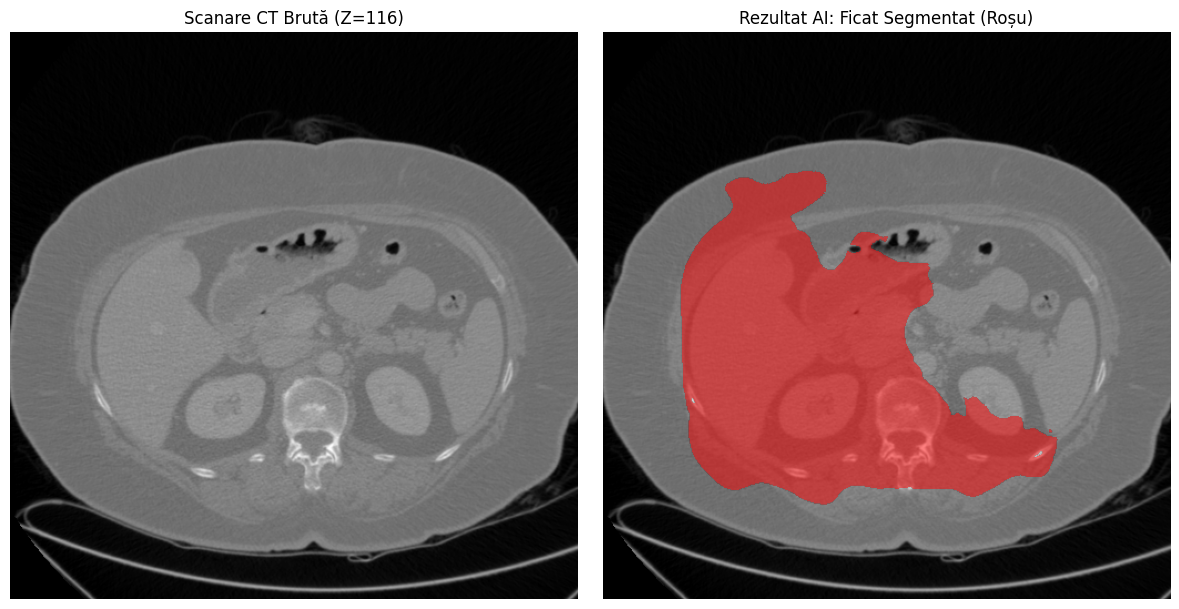

Post-procesare vizuala completa


In [9]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# 1. Definim căile către fișiere
base_dir = Path('/content/drive/MyDrive/[PI]Proiect_Segmentare_Organe')

# Numele trebuie să coincidă cu cel pe care l-ai pus la Modulul 5
nume_pacient = 'pacient_nou'

cale_ct_original = base_dir / 'inference_input' / f'{nume_pacient}_0000.nii.gz'
cale_masca_prezisa = base_dir / 'inference_output' / f'{nume_pacient}.nii.gz'

# Verificăm dacă fișierele există
if cale_ct_original.exists() and cale_masca_prezisa.exists():

    # 2. Încărcăm volumele 3D în memorie
    ct_nii = nib.load(cale_ct_original)
    mask_nii = nib.load(cale_masca_prezisa)

    ct_data = ct_nii.get_fdata()
    mask_data = mask_nii.get_fdata()

    # 3. Găsim automat felia (slice-ul) cu cea mai mare suprafață de ficat
    # Calculăm suma pixelilor de ficat pe axa Z
    arie_ficat_per_felie = np.sum(mask_data, axis=(0, 1))
    best_slice = np.argmax(arie_ficat_per_felie)

    # 4. Extragem felia respectivă (și o rotim la 90 de grade pentru a fi în poziție anatomică standard)
    felie_ct = np.rot90(ct_data[:, :, best_slice])
    felie_mask = np.rot90(mask_data[:, :, best_slice])

    # 5. Generăm figura grafică
    plt.figure(figsize=(12, 6))

    # Imaginea 1: CT-ul original brut
    plt.subplot(1, 2, 1)
    plt.imshow(felie_ct, cmap='gray')
    plt.title(f'Scanare CT Brută (Z={best_slice})')
    plt.axis('off')

    # Imaginea 2: Overaly (CT + Masca Prezisă de AI)
    plt.subplot(1, 2, 2)
    plt.imshow(felie_ct, cmap='gray')
    # Folosim o hartă de culori (jet) cu opacitate (alpha) pentru a vedea țesutul dedesubt
    # mask_data are valoarea 0 (fundal) si 1 (ficat). Ascundem fundalul cu np.ma.masked_where
    masca_transparenta = np.ma.masked_where(felie_mask == 0, felie_mask)
    plt.imshow(masca_transparenta, cmap='autumn', alpha=0.5)
    plt.title('Rezultat AI: Ficat Segmentat (Roșu)')
    plt.axis('off')

    plt.tight_layout()

    # 6. Salvam imaginea pe drive
    cale_imagine = base_dir / 'inference_output' / f'{nume_pacient}_overlay.png'
    plt.savefig(cale_imagine, dpi=300, bbox_inches='tight') # dpi=300 pentru claritate maximă

    plt.show()

    print("Post-procesare vizuala completa")
else:
    print("Eroare la vizualizare!")